# Animal Analysis Example
This notebook demonstrates animal-level analysis functions for tracking performance across sessions


In [3]:
from ethopy_analysis.data.loaders import get_sessions, get_mouse_weight
from ethopy_analysis.data.analysis import get_performance, get_no_repeat_performance, get_response_counts, weight_check
from ethopy_analysis.plots.animal import (
    plot_session_performance,
    plot_session_no_repeat_performance,
    plot_performance_liquid,
    plot_session_date,
    plot_trial_per_session,
    plot_animal_weight,
    plot_response_counts,
)

# Apply plot styling (optional)
from ethopy_analysis.config.styles import Style
Style().apply()

In [21]:
# Load session data for a specific animal
# get_sessions() retrieves all sessions for an animal
# Parameters: animal_id (int), min_trials (int), from_date (str), to_date (str), format ('df'/'dj')

animal_id = 484
min_trials = 20
sessions = get_sessions(animal_id, min_trials=min_trials)

# examples
# get_sessions(animal_id, min_trials=20, from_date="2023-01-01", to_date="2023-12-31")
# get_sessions(animal_id, min_trials=20 format="dj") # DataJoint format

# difficulty options:
#   None   -> one "total" line across sessions, using all trials (ignores difficulty)
#   "All"  -> one colored line per difficulty that exists in the sessions
#   [1, 2] -> one colored line per listed difficulty (sessions without them are skipped)
difficulties = None

Available difficulties: -9, -2, -1, 0, 1


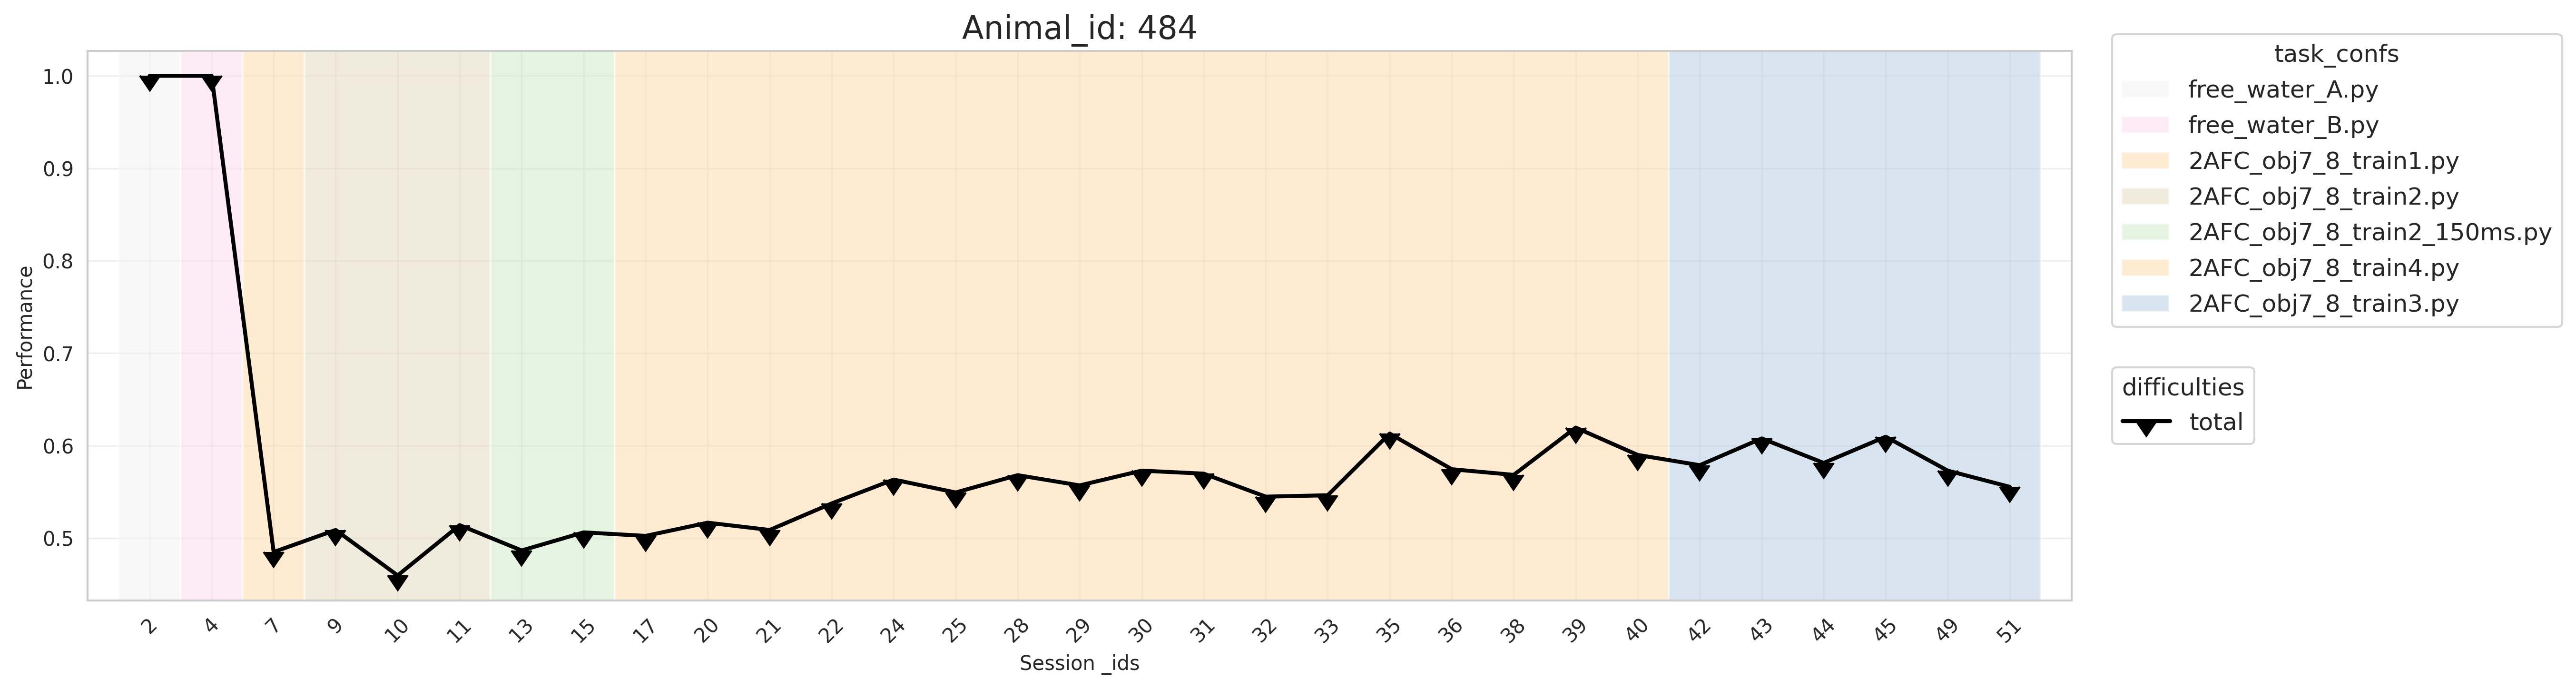

In [22]:
# Plot performance across sessions with protocol name visualization
# plot_session_performance() creates line plot showing performance over time
# Parameters: animal_id (int), sessions (List[int]), perf_func (callable), save_path (str), difficulty (None, 'All', or list)
# Returns: List of performance values for each session

perfs = plot_session_performance(animal_id, sessions['session'].values, perf_func=get_performance, difficulty=difficulties)

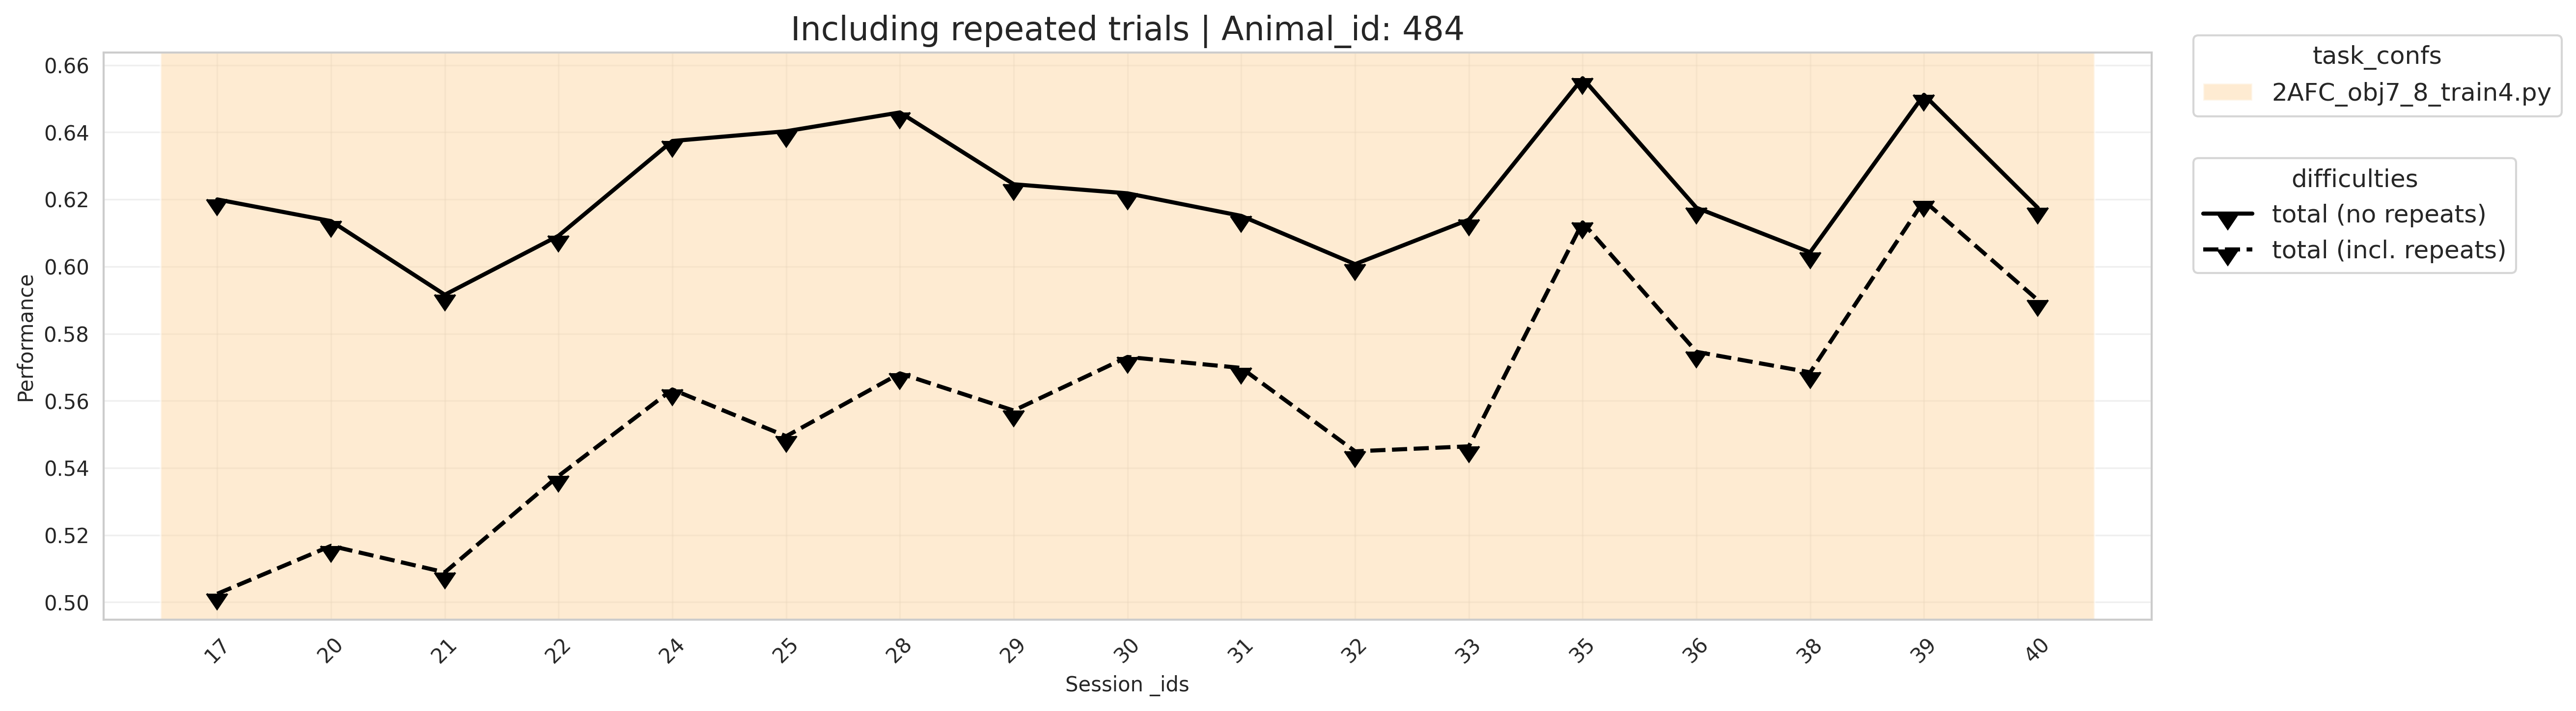

In [23]:
# Plot performance across sessions without repeated trials, one color per difficulty
# plot_session_no_repeat_performance() creates a solid line per difficulty (no repeated trials)
# repeat_line=True adds a dashed line per difficulty, in the same color (including repeated trials)
# Parameters: animal_id (int), sessions (List[int])
# perf_func (callable): get_no_repeat_performance, called as perf_func(animal_id, session, difficulty)
# save_path (str): optional path to save the figure
# repeat_line (bool): True adds the dashed "incl. repeats" line
# difficulty (None or list)
# Returns: dict mapping each line label (e.g. "difficulty 2 (no repeats)") to its performance values

perfs_no_repeat = plot_session_no_repeat_performance(
    animal_id, sessions['session'].values[8:25], perf_func=get_no_repeat_performance,
    repeat_line=True,
    difficulty=difficulties,
)

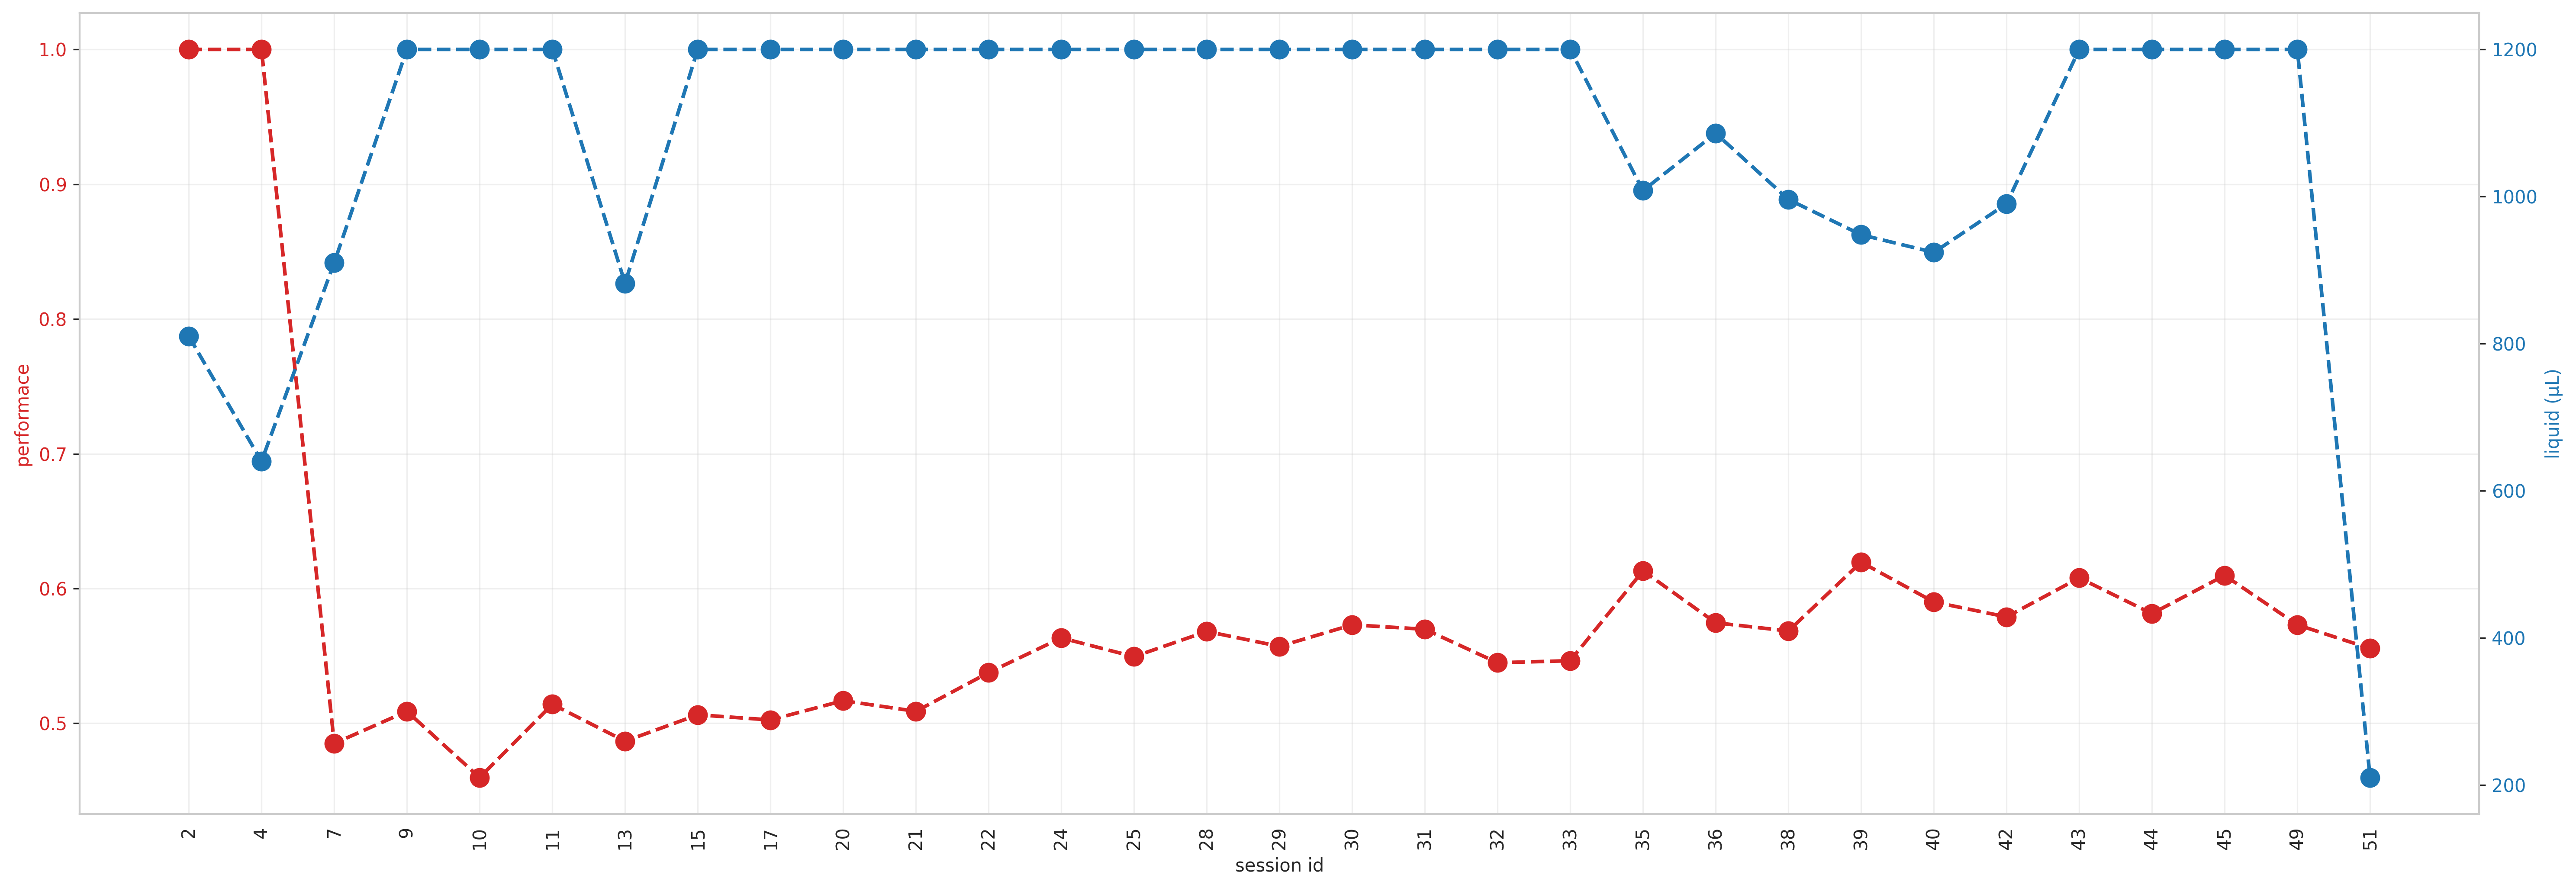

In [24]:
# Plot performance vs liquid reward consumption
# plot_performance_liquid() creates dual-axis plot showing behavior and reward consumption
# Parameters: animal_id (int), animal_sessions (DataFrame), xaxis ('session'/'date'), save_path (str)

plot_performance_liquid(animal_id, sessions, xaxis='session')  # xaxis = 'date' or 'session'

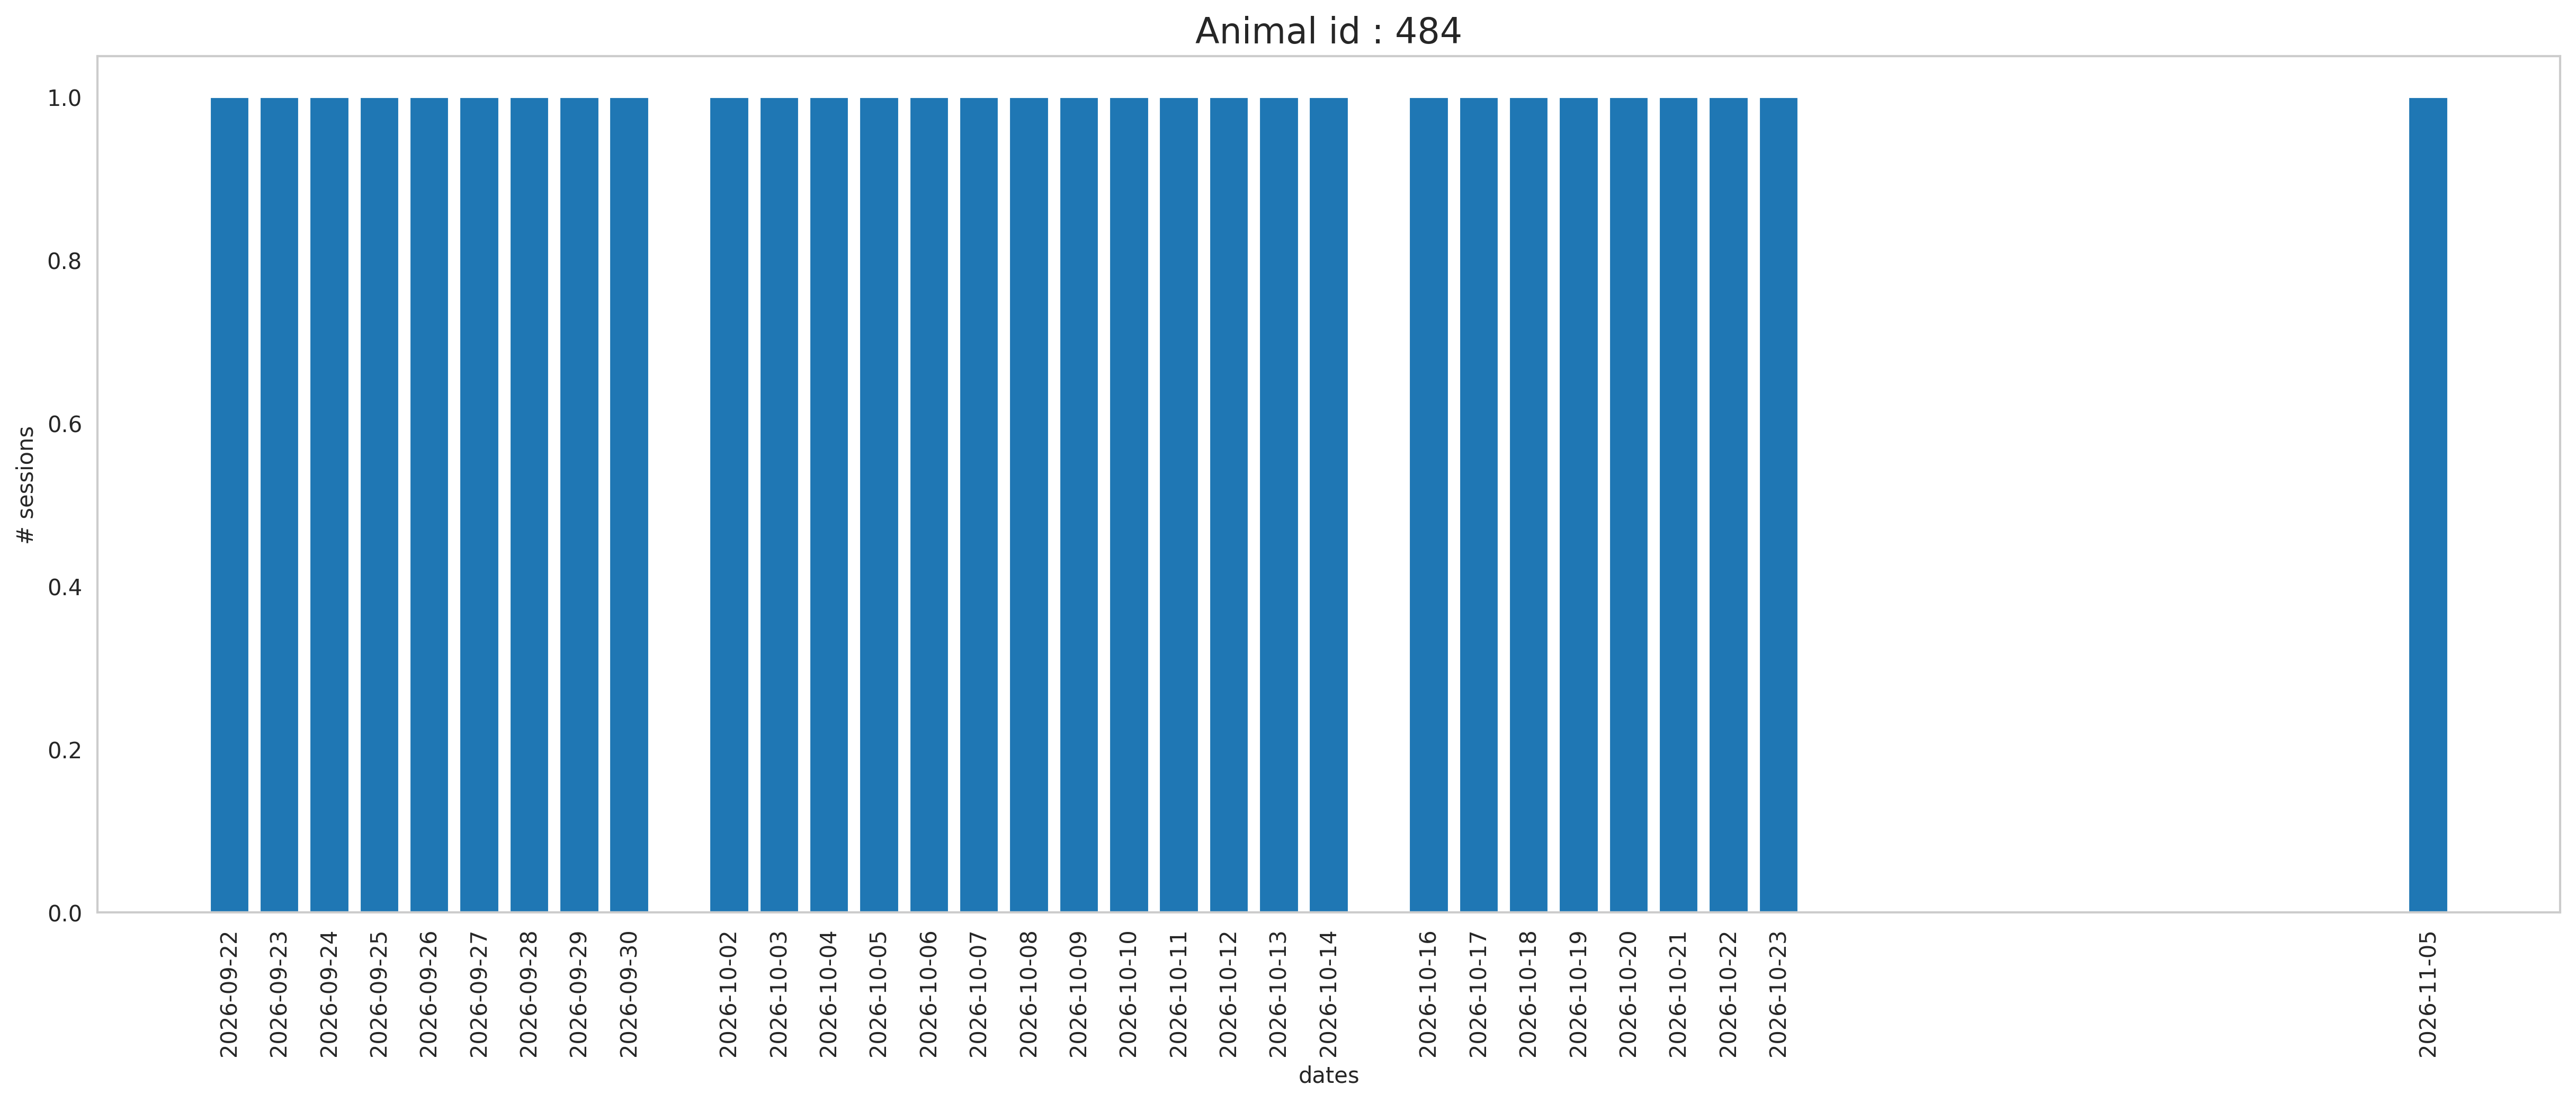

In [25]:
# Plot sessions per date to visualize training schedule
# plot_session_date() creates bar chart showing number of sessions per date
# Parameters: animal_id (int), min_trials (int), save_path (str)
# Returns: Dict mapping each date to list of session IDs

sessions_per_date = plot_session_date(animal_id, min_trials=min_trials)

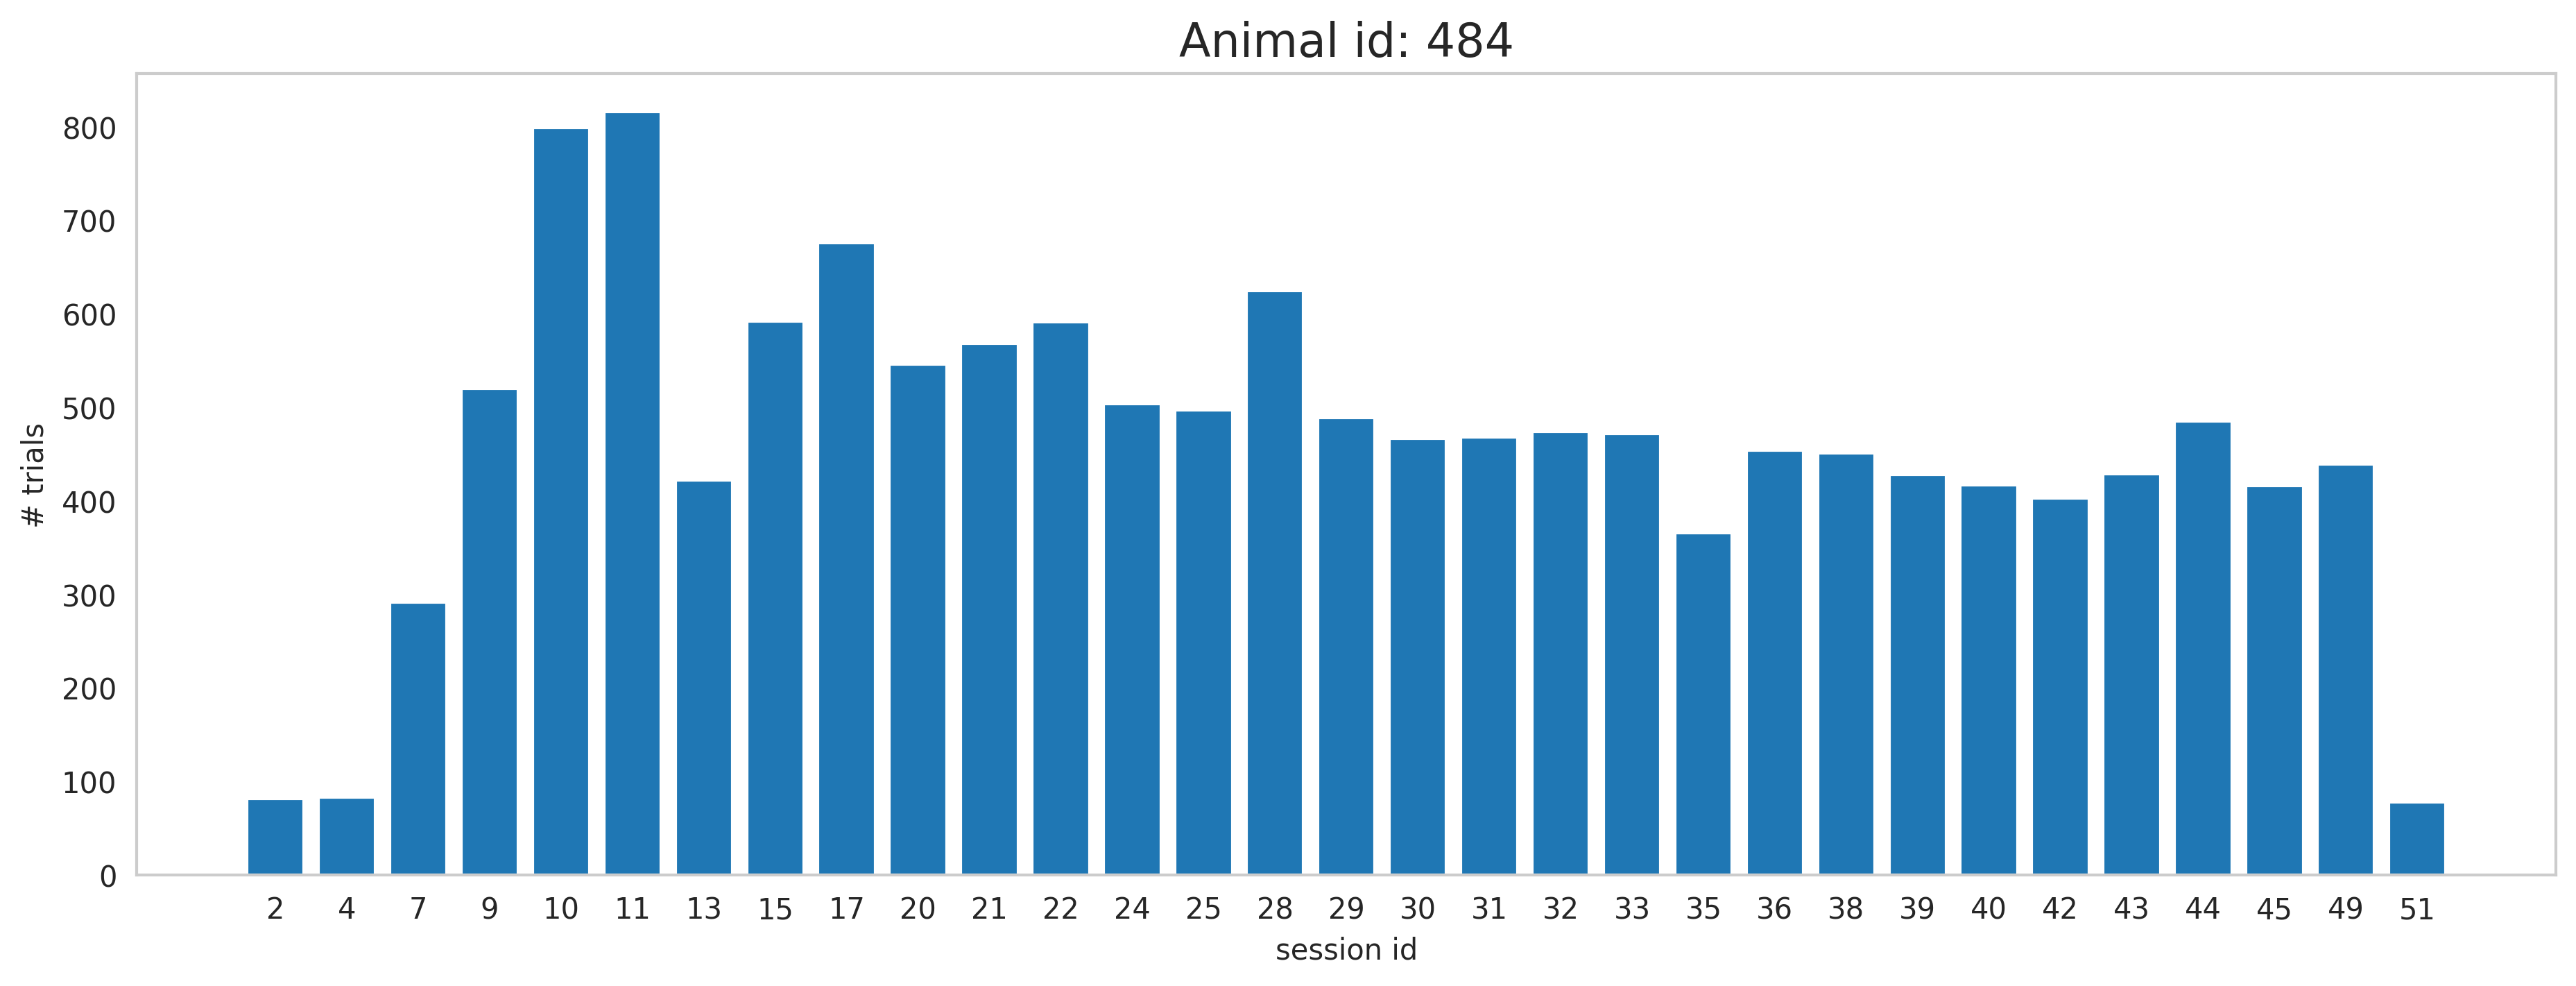

In [26]:
# Plot distribution of trials per session
# plot_trial_per_session() creates bar chart showing trial counts per session
# Parameters: animal_id (int), min_trials (int), save_path (str)

plot_trial_per_session(animal_id, min_trials=min_trials)

In [27]:
# Count and plot Reward, Punish and Abort trials per session
# get_response_counts() queries the database; plot_response_counts() draws the bars
# Parameters: animal_id, sessions (List[int]), difficulties (list or None), min_trials (int)
# difficulties (None or list)
# min_trials: skip sessions with fewer Reward/Punish/Abort trials than this

response_counts = get_response_counts(animal_id, sessions['session'].values, difficulties=difficulties, min_trials=min_trials)


TypeError: get_response_counts() got an unexpected keyword argument 'min_trials'

## Animal weight

Requires the optional `mice` schema in your configuration, e.g. `"mice": "lab_mice"`.

In [ ]:
# Load the weight measurements of an animal, sorted by timestamp
# get_mouse_weight() returns a DataFrame with animal_id, timestamp and weight
# Parameters: animal_id (int), from_date (str), to_date (str), format ('df'/'dj')

weight_df = get_mouse_weight(animal_id)
weight_df.tail()

,animal_id,timestamp,weight
2,484,2026-09-22 13:30:00,18.53
3,484,2026-09-25 19:22:05,17.06
4,484,2026-10-09 15:42:41,18.89
5,484,2026-10-30 15:11:58,19.79
6,484,2026-11-12 17:22:11,20.52


In [ ]:
# Check the weight against the water deprivation reference weight
# weight_check() warns if the animal is under the limit or has not been weighted lately
# Parameters: animal_id (int), count_from (int), weight_days (int), weight_percentage (float)
# count_from -> index of the measurement used as reference, adjust it to the start of deprivation
# Returns: dict with reference_weight, last_weight, percentage and days_since_last

weight_check(animal_id, count_from=5, weight_days=8, weight_percentage=0.7, weight_df=weight_df)

{'reference_weight': 19.79,
 'last_weight': 20.52,
 'percentage': 103.69,
 'days_since_last': 5,
 'below_threshold': False,
 'overdue': False}

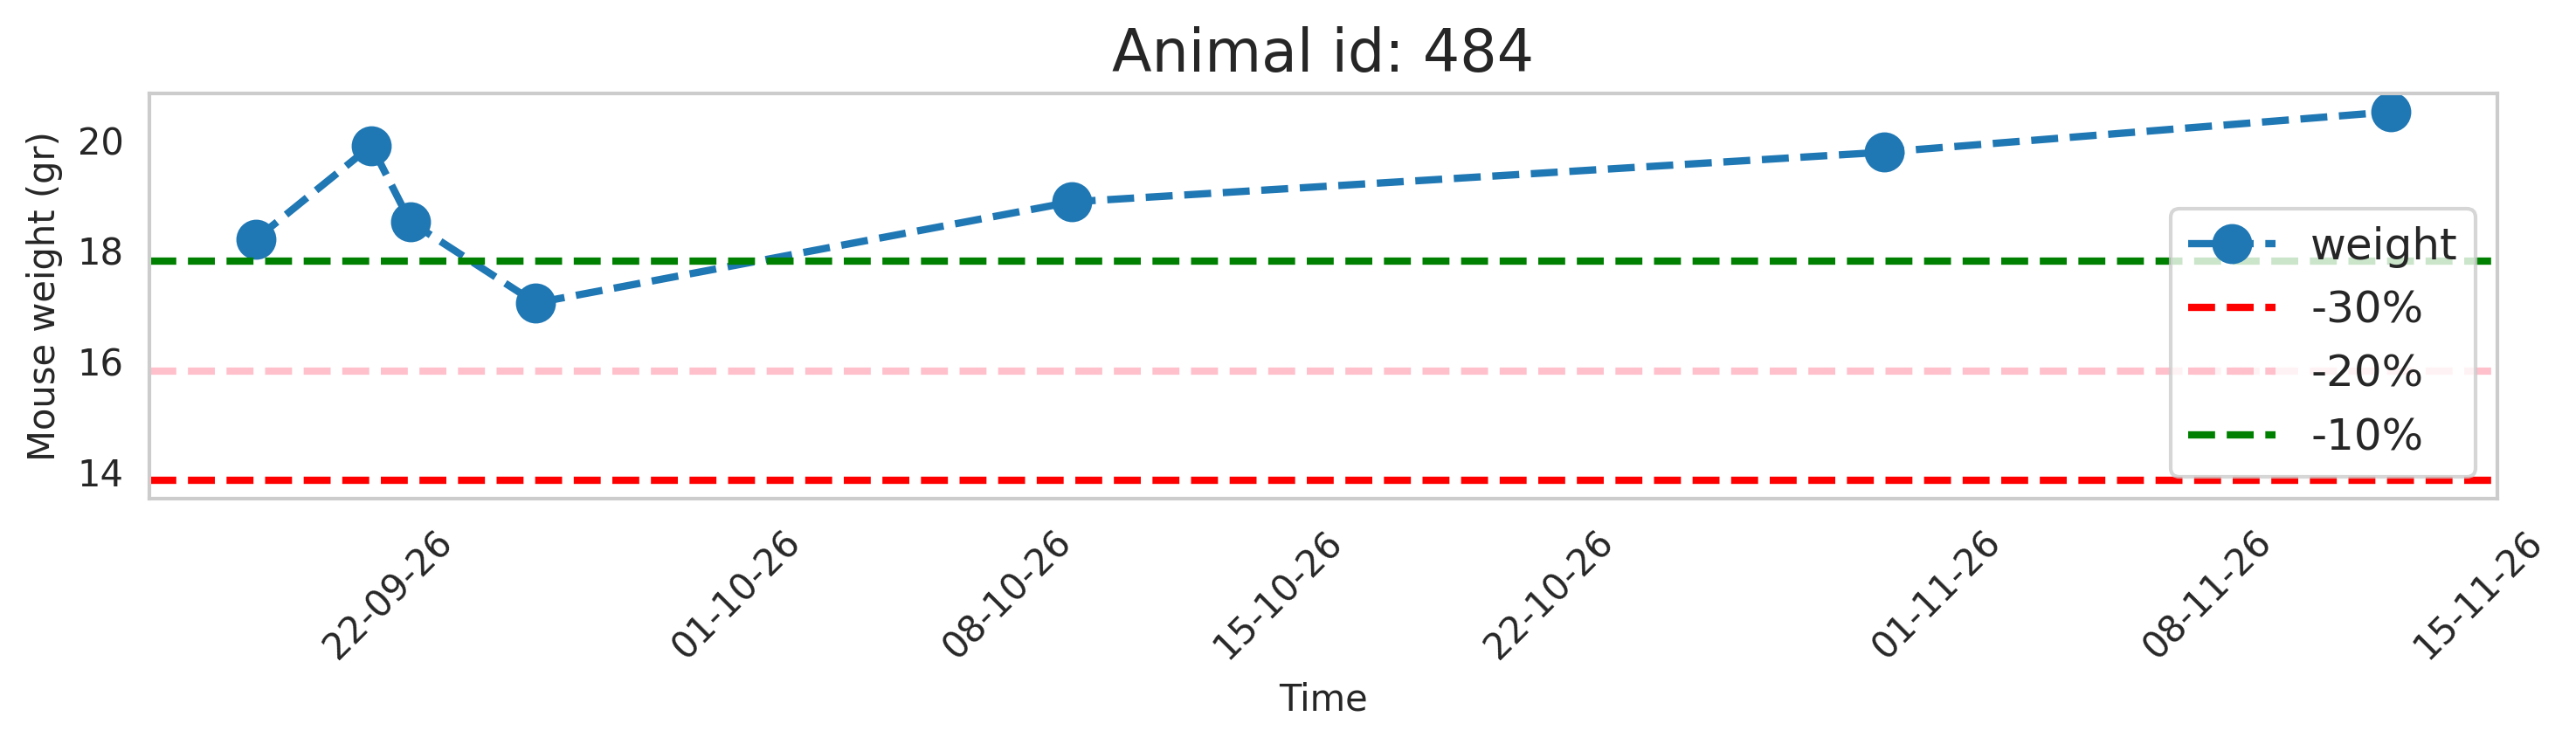

In [ ]:
# Plot the weight over time with the water deprivation limits
# plot_animal_weight() draws a line per measurement and one line per threshold
# Parameters: weight_df (DataFrame), animal_id (int), count_from (int), thresholds (tuple), save_path (str)

fig, ax = plot_animal_weight(weight_df, animal_id=animal_id, count_from=5)